# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: De Casa, Samantha Claire E.
- _Student No._: 2023-15141
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

**Figure 1. Synthetic data interpolation.** 
![Description](Synthetic_data_interpolation.png)

Figure 1 shows a graphical comparison between the curve of the original synthetic data and the curves of the interpolated reconstructions.

**Figure 2. Real-world data reconstruction.** 
![Description](Real_data_reconstruction1.png)

Figure 2.1 illustrates the reconstructed curves of a real-world dataset for varying sampling levels: 50%, 30%, 10%, and 5%.

![Description](Real_data_reconstruction2.png)

Figure 2.2 shows a graphical comparison between the reconstructed curves of a real-world dataset for different methods of interpolation: linear, nearest-neighbor, quadratic, and cubic.


### Report discussion

**Interpolator comparison:** Discuss how the interpolation methods differ and which reproduces the underlying function most accurately for the synthetic data.

Linear interpolation works by connecting consecutive sample points using straight lines. It is an excellent choice when the sample points are sufficiently close, but it struggles to reproduce the curvature of the sine function where the sample points are widely spaced. Nearest-neighbor interpolation, on the other hand, finds the closest known data point and copies it value directly. It produces a staircase-like graph, as can be seen in Figure 1, so it obviously fails to accurately represent the behavior of the sine function. Quadratic interpolation uses piecewise polynomial of degree two to approximate the function. Although it generally provides a good representation of the sine function, it introduces some deviations from the original curve when the sample points are sparse. In this problem, cubic interpolation, which uses piecewise polynomials of degree three to approximate the function, is the best choice for reproducing a smooth function like a sine curve.


**Sampling-level comparison:** Discuss how reconstruction quality changes as the number of sampled data points decreases. Mention limitations and any visible artifacts.

As the number of sampled data points decreases, the quality of the reconstruction generally deteriorates. This is particularly evident in Figure 2.1. With smaller sampling points, interpolation fails to accurately capture the fluctuations and trends in the original data. It removes finer details, causing the reconstruction curve to deviate from the original data.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

---

In [2]:
'''
this is just another way to generate random samples

x = np.linspace(-4, 4, 100)
y = lambda x: np.sin(x)

x_samples = np.random.choice(x, 50, replace = False)
y_samples = y(x_sampled)
'''

'\nthis is just another way to generate random samples\n\nx = np.linspace(-4, 4, 100)\ny = lambda x: np.sin(x)\n\nx_samples = np.random.choice(x, 50, replace = False)\ny_samples = y(x_sampled)\n'

In [3]:
n = 100 #sample size

x_samples = rng.uniform(-5, 5, n)
y_samples = np.sin(x_samples)

x = np.linspace(-5, 5, 200)

In [4]:
sorted_indices = np.argsort(x_samples)

x_sorted = x_samples[sorted_indices]
y_sorted = y_samples[sorted_indices]

In [5]:
linear = interpolate.make_interp_spline(x_sorted, y_sorted, k=1)(x) #linear interpolation
quadratic = interpolate.make_interp_spline(x_sorted, y_sorted, k=2)(x) #quadratic interpolation
cubic = interpolate.make_interp_spline(x_sorted, y_sorted, k=3)(x) #cubic interpolation

nearest = interpolate.interp1d(x_samples, y_samples, kind="nearest") #nearest interpolation
x_near = np.linspace(np.min(nearest.x), np.max(nearest.x), 200)

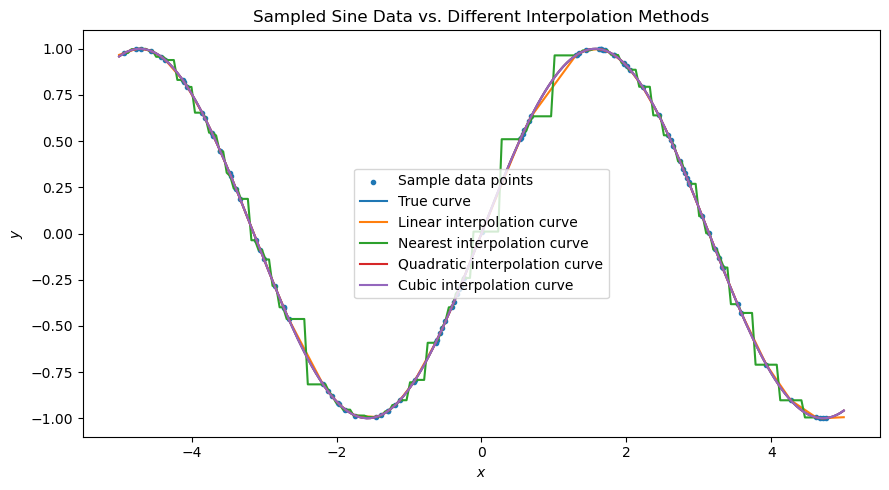

In [6]:
plt.figure(figsize=(9, 5))
plt.title("Sampled Sine Data vs. Different Interpolation Methods")
plt.xlabel(r"$x$")
plt.ylabel(r"$y$")
    
plt.scatter(x_samples, y_samples, label = "Sample data points", marker = ".")
plt.plot(x, np.sin(x), label = "True curve")
plt.plot(x, linear, label = "Linear interpolation curve")
plt.plot(x_near, nearest(x_near), label = "Nearest interpolation curve")
plt.plot(x, quadratic, label = "Quadratic interpolation curve")
plt.plot(x, cubic, label = "Cubic interpolation curve")

plt.legend()
plt.tight_layout()
plt.savefig("Synthetic_data_interpolation.png")
plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [7]:
filepath = "dow.txt"
raw_data = np.loadtxt(filepath)

values, indices = np.unique(raw_data, return_index = True)

In [8]:
gen_x = np.linspace(min(values), max(values), 750)

x50 = rng.choice(values, 512, replace = False) #50% sampling fraction
y50 = np.sin(x50)

x30 = rng.choice(values, 308, replace = False) #30% sampling fraction
y30 = np.sin(x30)

x10 = rng.choice(values, 103, replace = False) #10% sampling fraction
y10 = np.sin(x10)

x5 = rng.choice(values, 52, replace = False) #5% sampling fraction
y5 = np.sin(x5)

In [9]:
def sort(x, y):
    sorted_indices = np.argsort(x)
    x_sorted = x[sorted_indices]
    y_sorted = y[sorted_indices]
    return x_sorted, y_sorted

sorted50 = sort(x50, y50)
sorted30 = sort(x30, y30)
sorted10 = sort(x10, y10)
sorted5 = sort(x5, y5)

In [10]:
#my choice of interpolator is linear interpolation

linear50 = interpolate.make_interp_spline(sorted50[0], sorted50[1], k=1)(gen_x) #50% sampling fraction
linear30 = interpolate.make_interp_spline(sorted30[0], sorted30[1], k=1)(gen_x) #30% sampling fraction
linear10 = interpolate.make_interp_spline(sorted10[0], sorted10[1], k=1)(gen_x) #10% sampling fraction
linear5 = interpolate.make_interp_spline(sorted5[0], sorted5[1], k=1)(gen_x) #5% sampling fraction

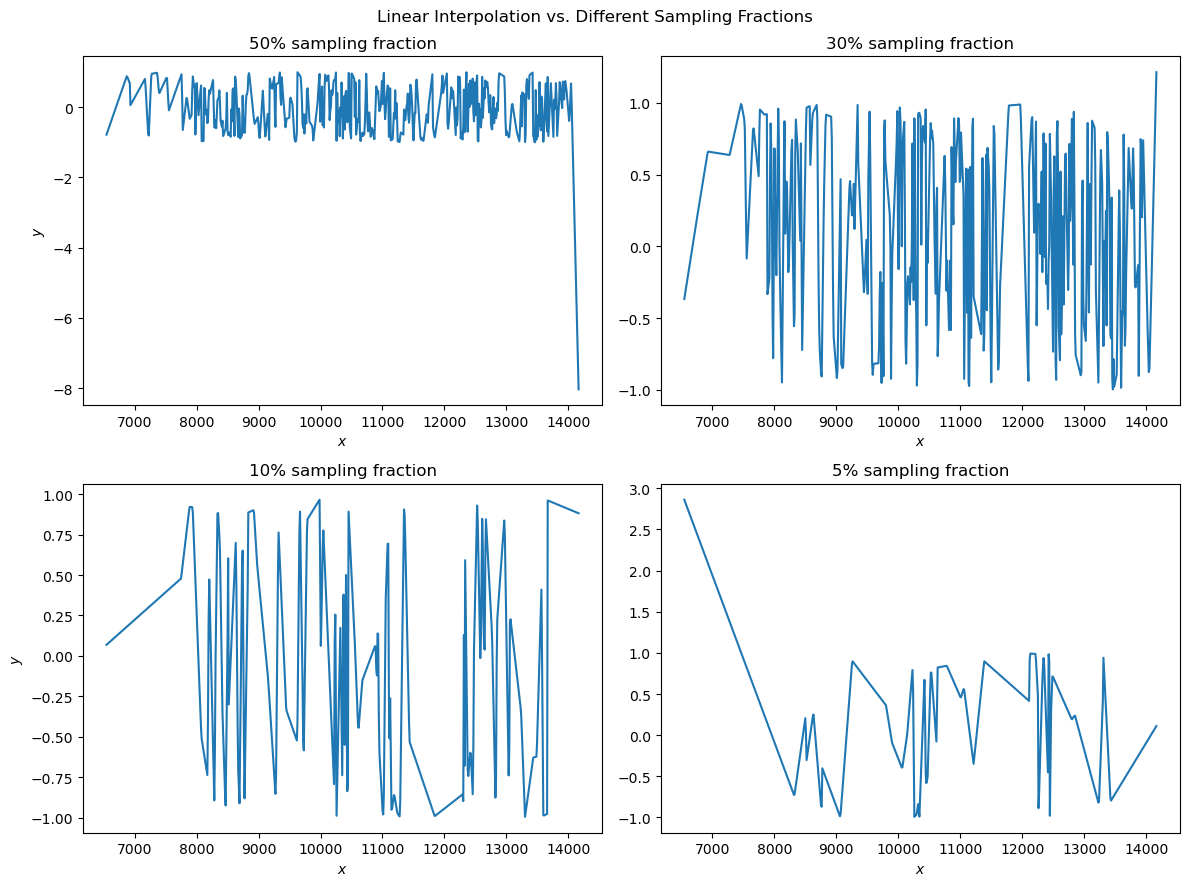

In [11]:
plt.figure(figsize=(12, 9))
plt.suptitle("Linear Interpolation vs. Different Sampling Fractions")

plt.subplot(2, 2, 1)
plt.plot(gen_x, linear50)
plt.title("50% sampling fraction")
plt.xlabel(r"$x$")
plt.ylabel(r"$y$")

plt.subplot(2, 2, 2)
plt.plot(gen_x, linear30) 
plt.title("30% sampling fraction")
plt.xlabel(r"$x$")

plt.subplot(2, 2, 3)
plt.plot(gen_x, linear10) 
plt.title("10% sampling fraction")
plt.xlabel(r"$x$")
plt.ylabel(r"$y$")

plt.subplot(2, 2, 4)
plt.plot(gen_x, linear5)
plt.title("5% sampling fraction")
plt.xlabel(r"$x$")

plt.tight_layout()
plt.savefig("Real_data_reconstruction1.png")
plt.show()

In [12]:
# load the dataset; download it first if needed
# path is https://websites.umich.edu/~mejn/cp/data/dow.txt

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

In [13]:
#my choice of sampling fraction is 30%

linear = interpolate.make_interp_spline(sorted30[0], sorted30[1], k=1)(gen_x) #linear interpolation
quadratic = interpolate.make_interp_spline(sorted30[0], sorted30[1], k=2)(gen_x) #quadratic interpolation
cubic = interpolate.make_interp_spline(sorted30[0], sorted30[1], k=3)(gen_x) #cubic interpolation

nearest = interpolate.interp1d(x30, y30, kind="nearest") #nearest interpolation
x_near = np.linspace(np.min(nearest.x), np.max(nearest.x), 400)

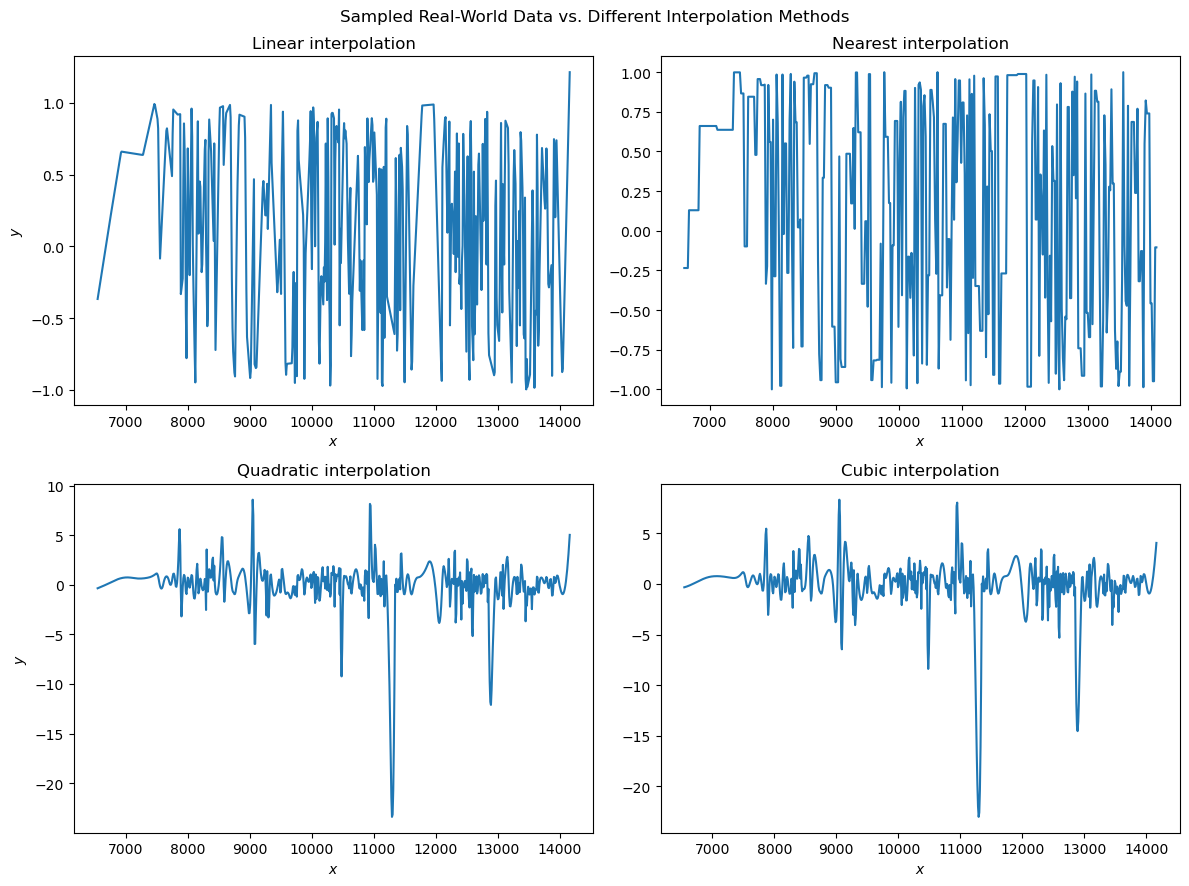

In [14]:
plt.figure(figsize=(12, 9))
plt.suptitle("Sampled Real-World Data vs. Different Interpolation Methods")

plt.subplot(2, 2, 1)
plt.plot(gen_x, linear)
plt.title("Linear interpolation")
plt.xlabel(r"$x$")
plt.ylabel(r"$y$")

plt.subplot(2, 2, 2)
plt.plot(x_near, nearest(x_near)) 
plt.title("Nearest interpolation")
plt.xlabel(r"$x$")

plt.subplot(2, 2, 3)
plt.plot(gen_x, quadratic) 
plt.title("Quadratic interpolation")
plt.xlabel(r"$x$")
plt.ylabel(r"$y$")

plt.subplot(2, 2, 4)
plt.plot(gen_x, cubic)
plt.title("Cubic interpolation")
plt.xlabel(r"$x$")

plt.tight_layout()
plt.savefig("Real_data_reconstruction2.png")
plt.show()

### Problem  code summary


The purpose of this script is to reconstruct the curves of the given datasets (synthetic and real-world) using the linear, nearest, quadratic, and cubic methods of interpolation. It also plots the given real-world data for various sampling sizes/fractions to determine how such a factor affects the reconstruction.

---